# Fractal subsystem constraints: counting $N_c$ with `torch.roll`

This notebook takes the six-neighbour operator identity

$$t_{i+e_1}+t_{i-e_1}+t_{i+e_2}+t_{i-e_2}+t_{i+e_1-e_2}+t_{i-e_1+e_2}=0 \pmod 2$$

and turns it into an explicit linear-algebra problem over $GF(2)$. Goal: $N_c = L_x + L_y + \text{GCD}(L_x, L_y) - 2$

**The logic in four steps:**

1. The six-roll-and-sum expression *is* a linear operator $A$ acting on lattice configurations $t$.
2. Feeding $A$ a single-site "delta" tensor returns one **column** of its matrix.
3. Doing that for all $L^2$ sites builds the full matrix.
4. The number of independent operator identities is $N_c = \dim\ker A$ — the configurations $t$ that
   satisfy the constraint at *every* site simultaneously.

The ground state degeneracy then follows as $\mathrm{GSD} = 2^{N_c}$ per plane.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

## 1. The operator: six rolls, summed mod 2

`torch.roll(t, shift, dim)` sets `new[k] = old[k - shift]`, and it **wraps around** — which
is exactly the periodic boundary condition, for free.

Convention used here: `dim=1` (columns) is the $e_1$ direction, `dim=0` (rows) is the $e_2$ direction.

Note the two double-rolls sample the **anti-diagonal** pair $(+1,-1)$ and $(-1,+1)$, i.e.
$e_1-e_2$ and $-e_1+e_2$ — matching the constraint. A square-lattice Laplacian would instead
include the main-diagonal corners $(\pm1,\pm1)$; the triangular lattice does not have those bonds.

In [2]:
SHIFTS = [(0, 1), (0, -1), (1, 0), (-1, 0), (-1, 1), (1, -1)]

def six_neighbor_sum(t):
    """Apply the six-neighbour constraint operator A to a configuration t (mod 2)."""
    out = torch.zeros_like(t)
    for (di, dj) in SHIFTS:
        out = out + torch.roll(torch.roll(t, di, 0), dj, 1)
    return out % 2

L = 4
rand_t = torch.randint(0, 2, (L, L))
print("Random configuration t:\n", rand_t.numpy())
print("\nA(t) — nonzero entries mark sites where the constraint is VIOLATED:")
print(six_neighbor_sum(rand_t).numpy())
print("\nA random t essentially never lands in the kernel. We must SOLVE, not sample.")

Random configuration t:
 [[1 0 1 1]
 [0 0 1 1]
 [1 1 0 0]
 [0 0 0 0]]

A(t) — nonzero entries mark sites where the constraint is VIOLATED:
[[0 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [0 0 1 1]]

A random t essentially never lands in the kernel. We must SOLVE, not sample.


## 2. A delta tensor exposes one column of the matrix

Apply $A$ to a configuration that is $1$ at a single site and $0$ elsewhere. By the definition of a
matrix, the output *is* that site's column of $A$. The result should be a ring of six 1s at exactly
the six neighbours.

In [3]:
def delta(L, i, j):
    e = torch.zeros((L, L), dtype=torch.int64)
    e[i, j] = 1
    return e

L = 5
e = delta(L, 2, 2)
resp = six_neighbor_sum(e)
print("Delta at (2,2):\n", e.numpy())
print("\nA(delta) = column of A — the six neighbours light up:\n", resp.numpy())
print("\nNumber of neighbours found:", int(resp.sum()))

Delta at (2,2):
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

A(delta) = column of A — the six neighbours light up:
 [[0 0 0 0 0]
 [0 0 1 1 0]
 [0 1 0 1 0]
 [0 1 1 0 0]
 [0 0 0 0 0]]

Number of neighbours found: 6


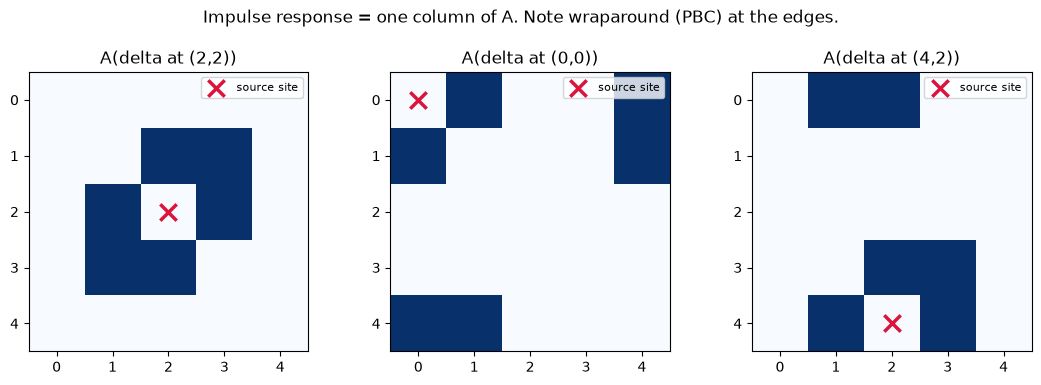

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (i, j) in zip(axes, [(2, 2), (0, 0), (4, 2)]):
    e = delta(L, i, j)
    r = six_neighbor_sum(e)
    ax.imshow(r.numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.scatter([j], [i], marker="x", s=140, c="crimson", linewidths=2.5, label="source site")
    ax.set_title(f"A(delta at ({i},{j}))")
    ax.set_xticks(range(L)); ax.set_yticks(range(L))
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Impulse response = one column of A. Note wraparound (PBC) at the edges.", y=1.02)
plt.tight_layout(); plt.show()

## 3. Build the full matrix $A$

Loop over all $L^2$ sites, stack the impulse responses as columns.

L=4: A has shape (16, 16)
Every column has exactly 6 ones: [6]
A is symmetric (neighbour relation is mutual): True


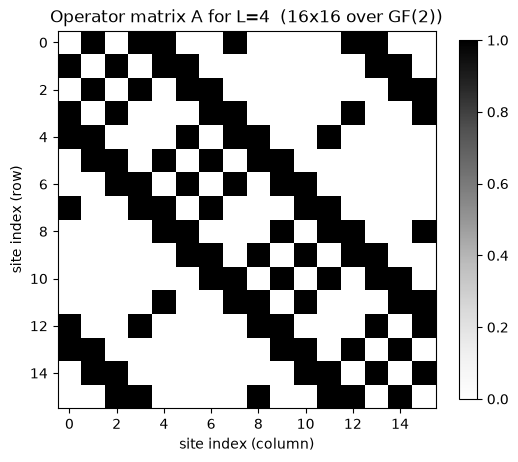

In [5]:
def build_matrix(L):
    N = L * L
    A = torch.zeros((N, N), dtype=torch.int64)
    for k in range(N):
        e = delta(L, k // L, k % L)
        A[:, k] = six_neighbor_sum(e).flatten()
    return A

L = 4
A = build_matrix(L)
print(f"L={L}: A has shape {tuple(A.shape)}")
print("Every column has exactly 6 ones:", torch.unique(A.sum(0)).tolist())
print("A is symmetric (neighbour relation is mutual):", bool((A == A.T).all()))

plt.figure(figsize=(5.5, 5))
plt.imshow(A.numpy(), cmap="Greys", interpolation="nearest")
plt.title(f"Operator matrix A for L={L}  ({L*L}x{L*L} over GF(2))")
plt.xlabel("site index (column)"); plt.ylabel("site index (row)")
plt.colorbar(shrink=0.8); plt.tight_layout(); plt.show()

## 4. Linear algebra over $GF(2)$ (Galois Field with only two elements)

We need rank and nullspace **over $GF(2)$**, not over the reals. Ordinary `torch.linalg`
routines work over floats and give the wrong answer here.

The only change from textbook Gaussian elimination: row operations use addition mod 2
(equivalently XOR), and $-1 = +1$, so "subtract" and "add" are the same operation.

In [6]:
def gf2_rref(M):
    """Row-reduced echelon form over GF(2). Returns (R, pivot_columns)."""
    M = M.clone() % 2
    rows, cols = M.shape
    pivots, r = [], 0
    for col in range(cols):
        piv = None
        for rr in range(r, rows):
            if M[rr, col] == 1:
                piv = rr
                break
        if piv is None:
            continue
        M[[r, piv]] = M[[piv, r]]
        for rr in range(rows):
            if rr != r and M[rr, col] == 1:
                M[rr] = (M[rr] + M[r]) % 2
        pivots.append(col)
        r += 1
        if r == rows:
            break
    return M, pivots

def gf2_rank(M):
    return len(gf2_rref(M)[1])

def gf2_nullspace(A):
    """Basis for {t : A t = 0} over GF(2), one vector per row."""
    R, pivots = gf2_rref(A)
    cols = A.shape[1]
    free = [c for c in range(cols) if c not in pivots]
    basis = []
    for f in free:
        v = torch.zeros(cols, dtype=torch.int64)
        v[f] = 1
        for i, p in enumerate(pivots):
            v[p] = R[i, f]
        basis.append(v)
    return torch.stack(basis) if basis else torch.zeros((0, cols), dtype=torch.int64)

A = build_matrix(4)
K = gf2_nullspace(A)
print(f"L=4 -> rank(A) = {gf2_rank(A)}, N_c = dim ker(A) = {K.shape[0]}")

L=4 -> rank(A) = 6, N_c = dim ker(A) = 10


## 5. Validation

Three independent checks, all of which must pass:

1. **Every kernel vector really is in the kernel** — verified by feeding it back through the
   original `six_neighbor_sum` roll function, not through the matrix. This closes the loop:
   the answer is checked against the code we started from.
2. **The kernel vectors are linearly independent** — their $GF(2)$ rank equals their count.
3. **Rank–nullity holds**: $\mathrm{rank}(A) + N_c = L^2$.

In [7]:
def validate(L, verbose=True):
    A = build_matrix(L)
    K = gf2_nullspace(A)
    Nc = K.shape[0]

    # Check 1: feed each kernel vector back through the ORIGINAL roll operator
    viol = 0
    for v in K:
        if six_neighbor_sum(v.reshape(L, L)).sum() != 0:
            viol += 1
    in_kernel = (viol == 0)

    # Check 2: linear independence over GF(2)
    independent = (gf2_rank(K) == Nc) if Nc > 0 else True

    # Check 3: rank-nullity
    rank_nullity = (gf2_rank(A) + Nc == L * L)

    if verbose:
        print(f"L={L}")
        print(f"  N_c                      = {Nc}   (3L-2 = {3*L-2})")
        print(f"  all vectors in kernel    : {in_kernel}  ({viol} violations)")
        print(f"  linearly independent     : {independent}  (rank of basis = {gf2_rank(K)})")
        print(f"  rank-nullity holds       : {rank_nullity}")
    return Nc, in_kernel, independent, rank_nullity

validate(4)

L=4
  N_c                      = 10   (3L-2 = 10)
  all vectors in kernel    : True  (0 violations)
  linearly independent     : True  (rank of basis = 10)
  rank-nullity holds       : True


(10, True, True, True)

In [8]:
print("Sweeping L = 2..12\n")
rows = []
for L in range(2, 13):
    Nc, a, b, cc = validate(L, verbose=False)
    rows.append((L, Nc, 3*L-2, a and b and cc))
    print(f"L={L:2d}  N_c={Nc:3d}   3L-2={3*L-2:3d}   matches={Nc==3*L-2}   all checks pass={a and b and cc}")

assert all(r[3] for r in rows), "a validation check failed"
print("\nAll validation checks passed.")

Sweeping L = 2..12

L= 2  N_c=  4   3L-2=  4   matches=True   all checks pass=True
L= 3  N_c=  7   3L-2=  7   matches=True   all checks pass=True
L= 4  N_c= 10   3L-2= 10   matches=True   all checks pass=True
L= 5  N_c= 13   3L-2= 13   matches=True   all checks pass=True
L= 6  N_c= 16   3L-2= 16   matches=True   all checks pass=True
L= 7  N_c= 19   3L-2= 19   matches=True   all checks pass=True
L= 8  N_c= 22   3L-2= 22   matches=True   all checks pass=True
L= 9  N_c= 25   3L-2= 25   matches=True   all checks pass=True
L=10  N_c= 28   3L-2= 28   matches=True   all checks pass=True
L=11  N_c= 31   3L-2= 31   matches=True   all checks pass=True
L=12  N_c= 34   3L-2= 34   matches=True   all checks pass=True

All validation checks passed.


## 6. The scaling result

$N_c = 3L-2$ for **every** $L$ — no gaps, no special sizes.

This is the physically important observation. For the TD (triangular-dipyramid) operator of the
paper, $N_c$ was zero for almost all $L$ and nonzero only at the number-theoretically special sizes
$L=2^n-2^m$; that sparseness is the fingerprint of fractal / type-II fracton physics and of UV/IR mixing.

Here $N_c$ grows smoothly and linearly with $L$ — generic subsystem-symmetry behaviour, **not** fractal.
Whatever fractal structure the three-layer operator carries must therefore come from the vertical
(inter-layer) coupling, not from this isotropic in-plane term alone.

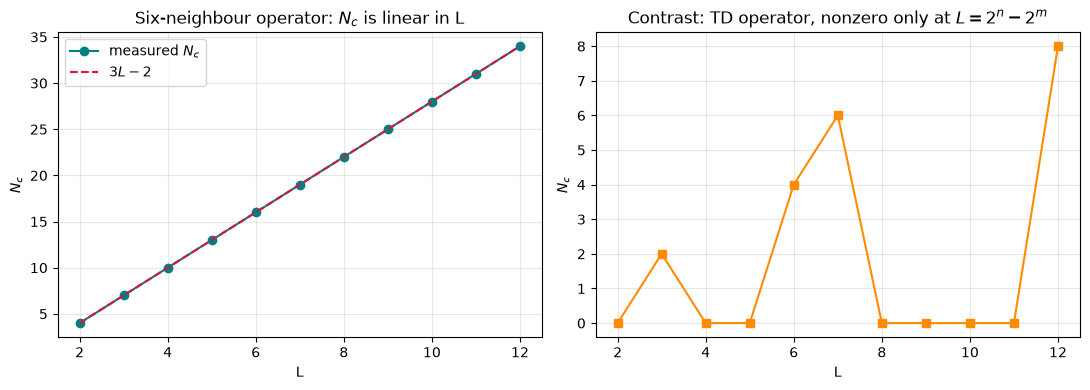

In [9]:
Ls = [r[0] for r in rows]
Ncs = [r[1] for r in rows]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(Ls, Ncs, "o-", label="measured $N_c$", color="teal")
ax[0].plot(Ls, [3*L-2 for L in Ls], "--", label="$3L-2$", color="crimson")
ax[0].set_xlabel("L"); ax[0].set_ylabel("$N_c$")
ax[0].set_title("Six-neighbour operator: $N_c$ is linear in L")
ax[0].legend(); ax[0].grid(alpha=0.3)

# contrast: the TD-operator / Sierpinski rule from the paper
def td_Nc(L):
    for n in range(2, 14):
        for m in range(0, n - 1):
            if 2**n - 2**m == L:
                return 2**n - 2**(m+1)
    return 0

ax[1].plot(Ls, [td_Nc(L) for L in Ls], "s-", color="darkorange")
ax[1].set_xlabel("L"); ax[1].set_ylabel("$N_c$")
ax[1].set_title("Contrast: TD operator, nonzero only at $L=2^n-2^m$")
ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## 7. Explicit results for the 4x4 lattice

$L=4$ gives $N_c = 10$, so $\mathrm{GSD} = 2^{10} = 1024$ per plane.

Below is every kernel basis vector printed and plotted as a $4\times4$ grid. Each one is a genuine
configuration of exponents $t_{ij}$ such that $\prod_p \mathcal{O}_p^{t_p} = \mathbb{1}$ identically —
i.e. an operator identity, a redundant stabilizer constraint.

In [10]:
L = 4
A4 = build_matrix(L)
K4 = gf2_nullspace(A4)
print(f"L=4:  N_c = {K4.shape[0]},  GSD = 2^{K4.shape[0]} = {2**K4.shape[0]}\n")

for idx, v in enumerate(K4):
    g = v.reshape(L, L)
    print(f"--- basis vector v{idx}  (weight {int(g.sum())}) ---")
    print(g.numpy())
    print()

L=4:  N_c = 10,  GSD = 2^10 = 1024

--- basis vector v0  (weight 4) ---
[[1 1 1 1]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

--- basis vector v1  (weight 4) ---
[[0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]
 [0 0 0 0]]

--- basis vector v2  (weight 6) ---
[[1 1 1 0]
 [1 1 0 0]
 [1 0 0 0]
 [0 0 0 0]]

--- basis vector v3  (weight 4) ---
[[1 0 0 0]
 [0 1 1 0]
 [0 1 0 0]
 [0 0 0 0]]

--- basis vector v4  (weight 4) ---
[[0 1 0 0]
 [1 1 0 0]
 [0 0 1 0]
 [0 0 0 0]]

--- basis vector v5  (weight 4) ---
[[0 0 1 0]
 [0 1 1 0]
 [0 0 0 1]
 [0 0 0 0]]

--- basis vector v6  (weight 4) ---
[[0 1 1 0]
 [0 1 0 0]
 [0 0 0 0]
 [1 0 0 0]]

--- basis vector v7  (weight 4) ---
[[1 1 0 0]
 [0 0 1 0]
 [0 0 0 0]
 [0 1 0 0]]

--- basis vector v8  (weight 6) ---
[[0 1 1 0]
 [1 1 1 0]
 [0 0 0 0]
 [0 0 1 0]]

--- basis vector v9  (weight 4) ---
[[1 1 0 0]
 [1 0 0 0]
 [0 0 0 0]
 [0 0 0 1]]



In [20]:
(K4[3].reshape(L, L) + K4[7].reshape(L, L))%2

tensor([[0, 1, 0, 0],
        [0, 1, 0, 0],
        [0, 1, 0, 0],
        [0, 1, 0, 0]])

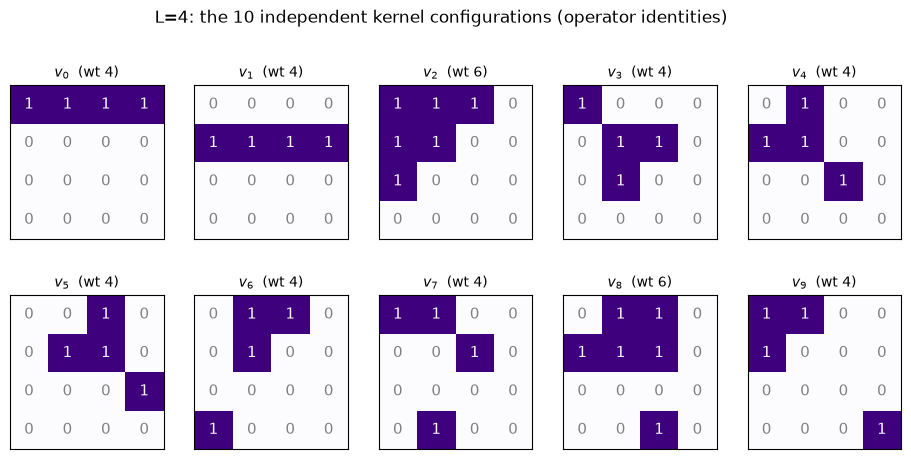

In [11]:
ncols = 5
nrows = int(np.ceil(K4.shape[0] / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.3*ncols, 2.5*nrows))
axes = np.atleast_1d(axes).ravel()

for idx, ax in enumerate(axes):
    if idx < K4.shape[0]:
        g = K4[idx].reshape(4, 4).numpy()
        ax.imshow(g, cmap="Purples", vmin=0, vmax=1)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, g[i, j], ha="center", va="center",
                        color="white" if g[i, j] else "gray", fontsize=11)
        ax.set_title(f"$v_{{{idx}}}$  (wt {int(g.sum())})", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.axis("off")

fig.suptitle("L=4: the 10 independent kernel configurations (operator identities)", y=1.01)
plt.show()

### Verify each one individually against the original roll code

The strongest check: take each basis vector, push it through the *exact* six-roll expression
we started with, and confirm the output grid is identically zero.

In [12]:
print("Per-vector verification against six_neighbor_sum (the original roll code):\n")
for idx, v in enumerate(K4):
    r = six_neighbor_sum(v.reshape(4, 4))
    print(f"  v{idx}:  A(v) all zero -> {bool((r == 0).all())}   (sum of residual = {int(r.sum())})")

print("\nPairwise independence spot-check (no vector is a sum of the others):")
for idx in range(K4.shape[0]):
    others = torch.cat([K4[:idx], K4[idx+1:]], dim=0)
    stacked = torch.cat([others, K4[idx:idx+1]], dim=0)
    print(f"  v{idx}: rank(others)={gf2_rank(others)}, rank(others+v{idx})={gf2_rank(stacked)}"
          f"  -> independent: {gf2_rank(stacked) > gf2_rank(others)}")

Per-vector verification against six_neighbor_sum (the original roll code):

  v0:  A(v) all zero -> True   (sum of residual = 0)
  v1:  A(v) all zero -> True   (sum of residual = 0)
  v2:  A(v) all zero -> True   (sum of residual = 0)
  v3:  A(v) all zero -> True   (sum of residual = 0)
  v4:  A(v) all zero -> True   (sum of residual = 0)
  v5:  A(v) all zero -> True   (sum of residual = 0)
  v6:  A(v) all zero -> True   (sum of residual = 0)
  v7:  A(v) all zero -> True   (sum of residual = 0)
  v8:  A(v) all zero -> True   (sum of residual = 0)
  v9:  A(v) all zero -> True   (sum of residual = 0)

Pairwise independence spot-check (no vector is a sum of the others):
  v0: rank(others)=9, rank(others+v0)=10  -> independent: True
  v1: rank(others)=9, rank(others+v1)=10  -> independent: True
  v2: rank(others)=9, rank(others+v2)=10  -> independent: True
  v3: rank(others)=9, rank(others+v3)=10  -> independent: True
  v4: rank(others)=9, rank(others+v4)=10  -> independent: True
  v5: ran

### Random linear combinations must also lie in the kernel

The kernel is a *vector space*: any $GF(2)$ sum of basis vectors is another valid operator identity.
This confirms we have a genuine subspace, not just a list of lucky configurations.

In [13]:
print("Random GF(2) combinations of the 10 basis vectors:\n")
for trial in range(6):
    coeffs = torch.randint(0, 2, (K4.shape[0],))
    combo = (coeffs @ K4) % 2
    r = six_neighbor_sum(combo.reshape(4, 4))
    print(f"  trial {trial}: coeffs={coeffs.tolist()}  ->  in kernel: {bool((r==0).all())}")

print(f"\nTotal configurations in the kernel: 2^{K4.shape[0]} = {2**K4.shape[0]}")

Random GF(2) combinations of the 10 basis vectors:

  trial 0: coeffs=[1, 1, 0, 0, 0, 1, 1, 1, 0, 0]  ->  in kernel: True
  trial 1: coeffs=[1, 0, 0, 1, 1, 0, 0, 1, 1, 0]  ->  in kernel: True
  trial 2: coeffs=[0, 1, 0, 0, 1, 1, 0, 0, 0, 0]  ->  in kernel: True
  trial 3: coeffs=[0, 0, 0, 1, 1, 1, 1, 1, 1, 1]  ->  in kernel: True
  trial 4: coeffs=[0, 1, 1, 0, 0, 0, 1, 0, 0, 1]  ->  in kernel: True
  trial 5: coeffs=[0, 0, 0, 1, 0, 1, 0, 0, 0, 0]  ->  in kernel: True

Total configurations in the kernel: 2^10 = 1024


## 8. Where to go next

1. **Explain $3L-2$ analytically.** Recall the multiplier factors as
   $xy\,P(x,y) = (1+x)(1+y)(x+y) \pmod 2$. Each of $\ker(1+x)$ and $\ker(1+y)$ is always
   exactly one-dimensional (spanned by the all-ones vector along that direction).
   Working out how the three kernels overlap should reproduce $3L-2$ in closed form — the
   $3$ plausibly counting the three lattice directions, the $-2$ counting the overcounted overlaps.

2. **Add the vertical direction.** The in-plane term alone is not fractal. Extend
   `six_neighbor_sum` with a third `torch.roll` along a $z$ axis (tensor shape `(Lz, L, L)`)
   to encode the three-layer structure, rebuild the matrix, and see whether $N_c$ then develops
   the number-theoretic $L$-dependence characteristic of fractal subsystem symmetries.